
Persiapan Data & Feature Engineering (RFM)


In [2]:
import pandas as pd
import numpy as np
import datetime as dt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv('olist_orders_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')

# menggabungkan tabel utama
df = orders.merge(payments, on='order_id').merge(customers, on='customer_id')

# menentukan tanggal referensi (misal: 1 hari setelah transaksi terakhir di dataset)
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
snapshot_date = df['order_purchase_timestamp'].max() + dt.timedelta(days=1)

# menghitung metrik RFM per customer_unique_id
rfm = df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (snapshot_date - x.max()).days, # Recency
    'order_id': 'count', # Frequency
    'payment_value': 'sum' # Monetary
}).reset_index()

rfm.columns = ['customer_unique_id', 'Recency', 'Frequency', 'Monetary']
print(rfm.head())

                 customer_unique_id  Recency  Frequency  Monetary
0  0000366f3b9a7992bf8c76cfdf3221e2      161          1    141.90
1  0000b849f77a49e4a4ce2b2a4ca5be3f      164          1     27.19
2  0000f46a3911fa3c0805444483337064      586          1     86.22
3  0000f6ccb0745a6a4b88665a16c9f078      370          1     43.62
4  0004aac84e0df4da2b147fca70cf8255      337          1    196.89



Preprocessing & Scaling


In [3]:
# Log transformation untuk mengatasi skewness data e-commerce
rfm_log = rfm[['Recency', 'Frequency', 'Monetary']].apply(np.log1p, axis=1)

# Scaling data agar rata-rata = 0 dan varians = 1
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])


 Pemodelan K-Means Clustering


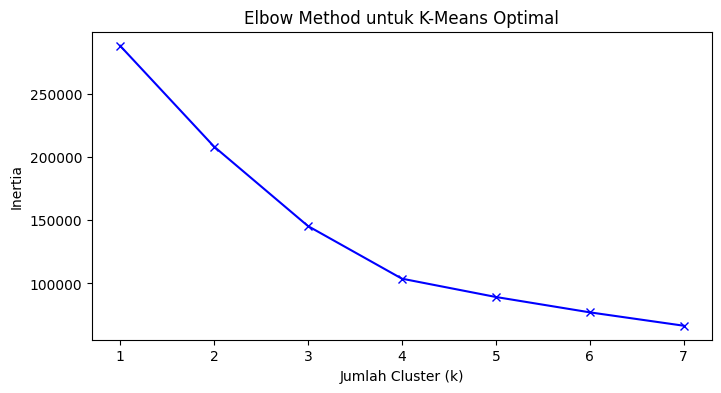

In [4]:
# Menentukan jumlah cluster menggunakan Elbow Method
inertia = []
K = range(1, 8)
for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, inertia, 'bx-')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method untuk K-Means Optimal')
plt.show()

# Pilihlah k optimal berdasarkan sikut grafik (misal: k=3 atau k=4)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_transform(rfm_scaled).argmax(axis=1) # Menyimpan label cluster


 Analisis Karakteristik Kluster (Profiling)


In [5]:
# Melihat rata-rata RFM di setiap cluster untuk interpretasi bisnis
cluster_analysis = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'customer_unique_id': 'count'
}).rename(columns={'customer_unique_id': 'Total Customers'}).reset_index()

print(cluster_analysis)


   Cluster     Recency  Frequency    Monetary  Total Customers
0        0  375.988919   2.375405  227.866578             3700
1        1  130.863972   2.331690  277.424781             2029
2        2  288.702609   1.000000  161.596960            90366
